# 02 · Diffusion vs GBM vs real

Both generators produce 2,000 windows of 64 days. Everything is compared against the real 2020–2024 holdout, which neither generator saw. The numbers here are re-read from `docs/phase08_results.json`, the same file the README is checked against.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from src import config, data, metrics
ds = data.load_dataset(ROOT / "data" / "processed" / "windows.npz")
runs = ROOT / "runs"
res = json.loads((ROOT / "docs" / "phase08_results.json").read_text())
src = {"real_test": ds["test_eval"], "gbm": np.load(runs / "gbm" / "samples.npy"),
       "diffusion": np.load(runs / res["run"] / "samples.npy")}
print("diffusion run:", res["run"])
colors = {"real_test": "#222222", "gbm": "#d1495b", "diffusion": "#2e86ab"}

diffusion run: r1_lr2e-4_20k


## Sample paths

Cumulative sums of 8 random windows from each source. GBM paths all look alike. Real and diffusion paths mix calm windows with wild ones.

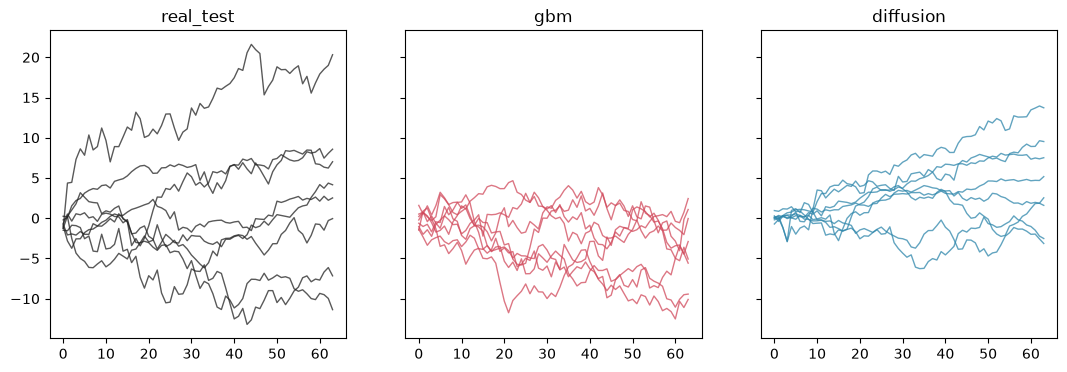

In [2]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for a, (k, w) in zip(ax, src.items()):
    for i in rng.choice(len(w), 8, replace=False):
        a.plot(np.cumsum(w[i]), color=colors[k], alpha=0.75, lw=1)
    a.set_title(k)

## The stylized-fact table

In [3]:
cols = ["excess_kurtosis", "skew", "acf_r_mean_abs", "acf_abs_mean", "acf_sq_mean", "wasserstein_to_real_test"]
print(f"{'':11s}" + "".join(f"{c[:14]:>16s}" for c in cols))
for k in ("real_test", "real_train", "gbm", "diffusion"):
    v = res["sources"][k]
    print(f"{k:11s}" + "".join(f"{v[c]:16.3f}" for c in cols))
res["criteria"]

             excess_kurtosi            skew  acf_r_mean_abs    acf_abs_mean     acf_sq_mean  wasserstein_to
real_test             8.446          -0.195           0.051           0.250           0.233           0.000
real_train           13.177          -0.032           0.025           0.240           0.180           0.128
gbm                   0.021          -0.004           0.003          -0.002          -0.002           0.146
diffusion             6.499          -0.312           0.009           0.053           0.032           0.352


{'vol_clustering_closer_than_gbm': True,
 'kurtosis_closer_than_gbm': True,
 'skew_closer_than_gbm': True,
 'linear_acf_not_above_real': True,
 'wasserstein_below_gbm': False}

## Headline: volatility clustering

The ACF of |r| is where a learned generator must separate from GBM. GBM's i.i.d. Gaussian returns give a flat zero line by construction.

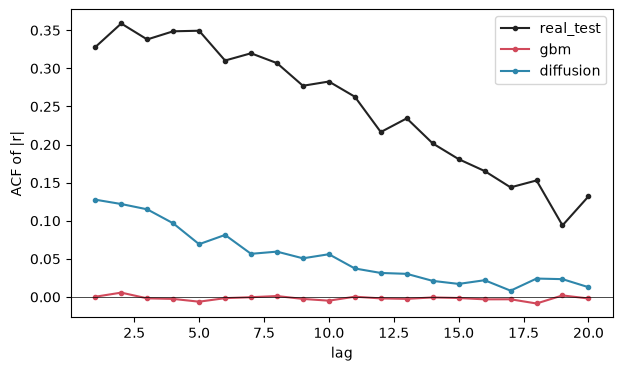

In [4]:
lags = np.arange(1, config.ACF_LAGS + 1)
plt.figure(figsize=(7, 4))
for k in ("real_test", "gbm", "diffusion"):
    plt.plot(lags, res["sources"][k]["acf_abs"], "o-", ms=3, color=colors[k], label=k)
plt.axhline(0, color="k", lw=0.5); plt.xlabel("lag"); plt.ylabel("ACF of |r|"); plt.legend()

## Tails

The Q-Q plot shows how far each source's tails stretch beyond a normal distribution.

Text(0, 0.5, 'sample quantile')

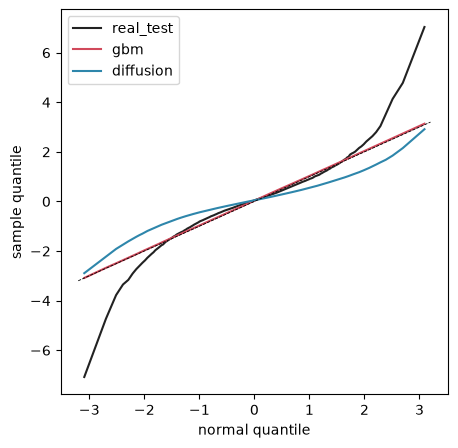

In [5]:
q = np.linspace(0.001, 0.999, 400)
plt.figure(figsize=(5, 5))
for k, w in src.items():
    plt.plot(stats.norm.ppf(q), np.quantile(w.ravel(), q), color=colors[k], label=k)
plt.plot([-3.2, 3.2], [-3.2, 3.2], "k--", lw=0.6); plt.legend(); plt.xlabel("normal quantile"); plt.ylabel("sample quantile")

See `docs/RESULTS.md` for the written interpretation and caveats.